# IFEval evaluation: figures

Qwen2.5-0.5B-Instruct on IFEval, measured with this repository's harness.

Every number below is read from `runs/` (the official scorer's per-item output and
the raw generations). The only values typed in by hand are the published reference
numbers, each with its source. Each chart is followed by a table with the same data,
and saved as a PNG under `report/figures/`.

Run from anywhere inside the repository with the notebook environment:
`pip install -r requirements-notebook.txt`.

## Setup

In [1]:
import collections
import hashlib
import json
import math
import pathlib
import subprocess
import sys

import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter

# Find the repository root, so the notebook works from any working directory.
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / "run.sh").exists():
    if ROOT.parent == ROOT:
        raise SystemExit("Open this notebook from inside the repository.")
    ROOT = ROOT.parent

# Same Wilson interval as report.json - imported, not re-typed.
sys.path.insert(0, str(ROOT / "src"))
from analyze import wilson

RUNS = ROOT / "runs"
FIGURES = ROOT / "report" / "figures"
FIGURES.mkdir(exist_ok=True)


def one(pattern):
    matches = sorted(RUNS.glob(pattern))
    assert len(matches) == 1, f"expected one run matching {pattern}, found {len(matches)}"
    return matches[0]


BASELINE = RUNS / "qwen05b_laptop_hf_20260916_004530"
REPEATS = sorted(RUNS.glob("qwen05b_laptop_hf_*"))      # the baseline and its repeats
VARIANTS = {
    "Qwen default (baseline)": BASELINE,
    '"You are a helpful assistant."': one("qwen05b_laptop_sys_generic_hf_*"),
    '"Follow every instruction exactly…"': one("qwen05b_laptop_sys_strict_hf_*"),
    '"Warm, conversational style"': one("qwen05b_laptop_sys_casual_hf_*"),
}

# Published reference values (typed in, with sources).
PAPER_TABLE3 = {   # Zhou et al. 2023, arXiv:2311.07911, Table 3
    "GPT-4":    {"Prompt strict": 76.89, "Instruction strict": 83.57,
                 "Prompt loose": 79.30, "Instruction loose": 85.37},
    "PaLM 2 S": {"Prompt strict": 43.07, "Instruction strict": 55.76,
                 "Prompt loose": 46.95, "Instruction loose": 59.11},
}
QWEN_REPORT = {"Qwen2.5-0.5B-Instruct": 27.9,   # Qwen2.5 Technical Report,
               "Qwen2.5-1.5B-Instruct": 42.5}   # arXiv:2412.15115

In [2]:
# Colours: validated reference palette (categorical slots 1-3, light mode).
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
QWEN = "#2a78d6"        # slot 1 - our model, in every chart
GPT4 = "#eb6834"        # slot 2 - GPT-4 reference, in every chart
TRUNCATED = "#1baf7a"   # slot 3 - responses cut off at the token limit
CONTEXT = "#c3c2b7"     # de-emphasis gray - published numbers for other models
GAINED, LOST = "#2a78d6", "#e34948"   # diverging poles: blue / red

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.edgecolor": AXIS, "axes.linewidth": 1,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1, "grid.linestyle": "-",
    "axes.axisbelow": True, "legend.frameon": False,
    "figure.dpi": 110, "savefig.dpi": 200,
})
DOT = dict(s=70, edgecolors=SURFACE, linewidths=2, zorder=3)   # >=8px dot, 2px surface ring


def read_jsonl(path):
    return [json.loads(line) for line in open(path, encoding="utf-8") if line.strip()]


def title(ax, heading, sub):
    ax.set_title(heading, pad=26)
    ax.annotate(sub, xy=(0, 1), xycoords="axes fraction", xytext=(0, 8),
                textcoords="offset points", color=INK_2, fontsize=9, va="bottom")


def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight")
    plt.show()


def table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |", "|" + "---|" * len(headers)]
    lines += ["| " + " | ".join(str(c) for c in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


def four_metrics(run):
    """(passed, total) for the four IFEval metrics, from the scorer's per-item files."""
    out = {}
    for mode in ("strict", "loose"):
        recs = read_jsonl(run / f"eval_results_{mode}.jsonl")
        flags = [f for r in recs for f in r["follow_instruction_list"]]
        out[f"Prompt {mode}"] = (sum(r["follow_all_instructions"] for r in recs), len(recs))
        out[f"Instruction {mode}"] = (sum(flags), len(flags))
    return out


def rates_by(run, group):
    """(passed, total) per instruction group, strict."""
    passed, total = collections.Counter(), collections.Counter()
    for r in read_jsonl(run / "eval_results_strict.jsonl"):
        for iid, ok in zip(r["instruction_id_list"], r["follow_instruction_list"]):
            total[group(iid)] += 1
            passed[group(iid)] += bool(ok)
    return {g: (passed[g], total[g]) for g in total}


def prompt_pass(run):
    return {r["prompt"]: r["follow_all_instructions"]
            for r in read_jsonl(run / "eval_results_strict.jsonl")}


def md5(path):
    return hashlib.md5(path.read_bytes()).hexdigest()


def pct(k, n):
    return f"{100 * k / n:.1f}%"


METRICS = ["Prompt strict", "Instruction strict", "Prompt loose", "Instruction loose"]

## 0. Runs and repeatability

The baseline was run four times with identical settings. Identical `generations.jsonl`
hashes mean the model produced exactly the same text every time.

In [3]:
rows = []
for run in REPEATS + list(VARIANTS.values())[1:]:
    commit = next(line.split(": ", 1)[1] for line in (run / "environment.txt").read_text().splitlines()
                  if line.startswith("git_commit"))
    m = four_metrics(run)
    rows.append([f"`{run.name}`", commit.split()[0][:8], md5(run / "generations.jsonl")[:10],
                 *(pct(*m[x]) for x in METRICS)])
table(["Run", "Commit", "Generations md5", *METRICS], rows)

hashes = {md5(run / "generations.jsonl") for run in REPEATS}
spread = [100 * four_metrics(run)["Instruction strict"][0] / 834 for run in REPEATS]
print(f"{len(REPEATS)} baseline runs -> {len(hashes)} distinct generations file(s)")
print(f"Instruction-level strict range: {min(spread):.2f}-{max(spread):.2f}% "
      "(scorer's random letter check only)")

| Run | Commit | Generations md5 | Prompt strict | Instruction strict | Prompt loose | Instruction loose |
|---|---|---|---|---|---|---|
| `qwen05b_laptop_hf_20260916_004530` | none | d8529cf262 | 26.6% | 36.7% | 29.0% | 39.1% |
| `qwen05b_laptop_hf_20260916_011950` | b8303f44 | d8529cf262 | 26.6% | 36.6% | 29.0% | 39.1% |
| `qwen05b_laptop_hf_20260916_013726` | fbdd4b14 | d8529cf262 | 26.6% | 36.6% | 29.0% | 39.1% |
| `qwen05b_laptop_hf_20260916_015502` | fbdd4b14 | d8529cf262 | 26.6% | 36.7% | 29.0% | 39.1% |
| `qwen05b_laptop_sys_generic_hf_20260916_021151` | fbdd4b14 | 99a5aab5c4 | 28.7% | 39.9% | 31.8% | 43.6% |
| `qwen05b_laptop_sys_strict_hf_20260916_022924` | fbdd4b14 | ef013ec710 | 26.4% | 37.4% | 29.6% | 41.2% |
| `qwen05b_laptop_sys_casual_hf_20260916_024446` | fbdd4b14 | 6787716348 | 27.0% | 36.8% | 29.6% | 39.6% |

4 baseline runs -> 1 distinct generations file(s)
Instruction-level strict range: 36.57-36.69% (scorer's random letter check only)


## 1. Validating the scorer against the paper

The scorer repository ships the GPT-4 responses used in the paper. They are scored once
through this harness's own `src/score.py` and cached in `reference/gpt4_paper/`.
Prompt 2785 was edited after the paper ("one" became "3 placeholders"), so its one
response is mapped onto the current wording.

In [4]:
REF = ROOT / "reference" / "gpt4_paper"
if not (REF / "eval_results_strict.jsonl").exists():
    REF.mkdir(parents=True, exist_ok=True)
    current = read_jsonl(ROOT / "data" / "input_data.jsonl")
    paper = read_jsonl(ROOT / "external" / "instruction_following_eval" / "data"
                       / "input_response_data_gpt4_20231107_145030.jsonl")
    now, then = {r["prompt"] for r in current}, {r["prompt"] for r in paper}
    assert len(then - now) == 1, "expected exactly one edited prompt"
    remap = {(then - now).pop(): (now - then).pop()}
    key_of = {r["prompt"]: r["key"] for r in current}
    with open(REF / "generations.jsonl", "w", encoding="utf-8") as f:
        for r in paper:
            prompt = remap.get(r["prompt"], r["prompt"])
            f.write(json.dumps({"key": key_of[prompt], "prompt": prompt,
                                "response": r["response"]}, ensure_ascii=False) + "\n")
    subprocess.run([sys.executable, "src/score.py", "--config", "configs/qwen05b.yaml",
                    "--out", str(REF)], cwd=ROOT, check=True, capture_output=True)

gpt4 = four_metrics(REF)
table(["GPT-4", "Paper (Table 3)", "Our scorer", "Difference"],
      [[x, f"{PAPER_TABLE3['GPT-4'][x]:.2f}", f"{100 * gpt4[x][0] / gpt4[x][1]:.2f}",
        f"{100 * gpt4[x][0] / gpt4[x][1] - PAPER_TABLE3['GPT-4'][x]:+.2f}"] for x in METRICS])

| GPT-4 | Paper (Table 3) | Our scorer | Difference |
|---|---|---|---|
| Prompt strict | 76.89 | 77.08 | +0.19 |
| Instruction strict | 83.57 | 83.69 | +0.12 |
| Prompt loose | 79.30 | 79.67 | +0.37 |
| Instruction loose | 85.37 | 85.61 | +0.24 |

## 2. Headline metrics

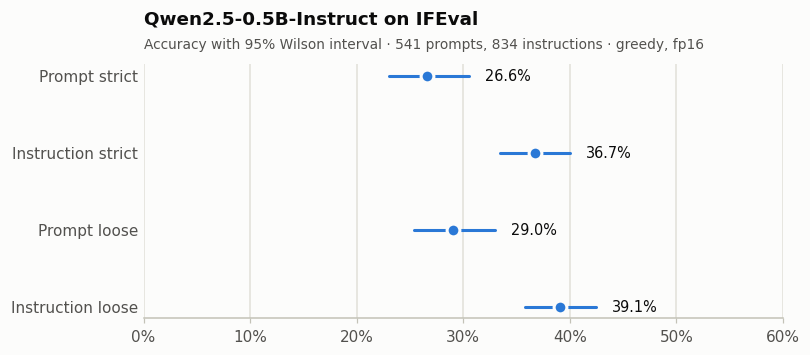

| Metric | Accuracy | 95% CI | Passed / total |
|---|---|---|---|
| Prompt strict | 26.6% | 23.1%–30.5% | 144 / 541 |
| Instruction strict | 36.7% | 33.5%–40.0% | 306 / 834 |
| Prompt loose | 29.0% | 25.4%–33.0% | 157 / 541 |
| Instruction loose | 39.1% | 35.8%–42.4% | 326 / 834 |

In [5]:
base = four_metrics(BASELINE)
fig, ax = plt.subplots(figsize=(7.5, 3.0))
for y, name in enumerate(reversed(METRICS)):
    k, n = base[name]
    lo, hi = wilson(k, n)
    ax.plot([100 * lo, 100 * hi], [y, y], color=QWEN, lw=2, solid_capstyle="round", zorder=2)
    ax.scatter([100 * k / n], [y], color=QWEN, **DOT)
    ax.text(100 * hi + 1.5, y, f"{100 * k / n:.1f}%", va="center", color=INK, fontsize=9.5)
ax.set_yticks(range(len(METRICS)), list(reversed(METRICS)))
ax.tick_params(axis="y", length=0)
ax.set_xlim(0, 60)
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
title(ax, "Qwen2.5-0.5B-Instruct on IFEval",
      "Accuracy with 95% Wilson interval · 541 prompts, 834 instructions · greedy, fp16")
save(fig, "01_headline_metrics")

table(["Metric", "Accuracy", "95% CI", "Passed / total"],
      [[x, pct(*base[x]), "–".join(f"{100 * v:.1f}%" for v in wilson(*base[x])),
        f"{base[x][0]} / {base[x][1]}"] for x in METRICS])

## 3. Comparison with published numbers

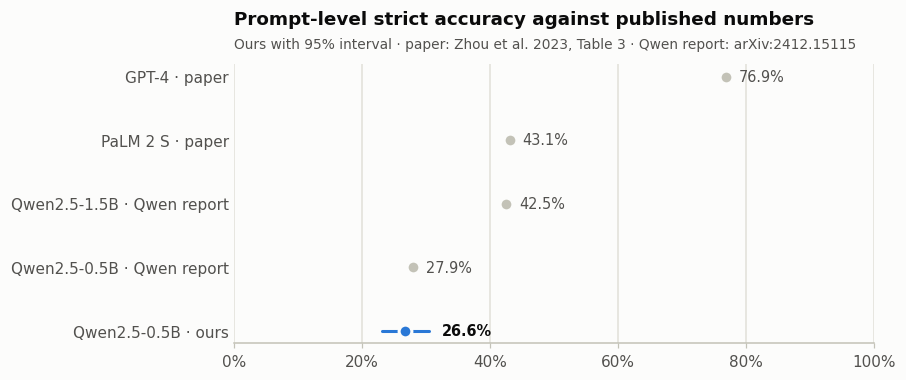

| Model | Prompt-level strict | Gap to ours (points) |
|---|---|---|
| GPT-4 · paper | 76.9% | -50.3 |
| PaLM 2 S · paper | 43.1% | -16.5 |
| Qwen2.5-1.5B · Qwen report | 42.5% | -15.9 |
| Qwen2.5-0.5B · Qwen report | 27.9% | -1.3 |
| Qwen2.5-0.5B · ours | 26.6% | — |

In [6]:
k, n = base["Prompt strict"]
lo, hi = wilson(k, n)
models = [   # (label, prompt-level strict %, is ours)
    ("GPT-4 · paper", PAPER_TABLE3["GPT-4"]["Prompt strict"], False),
    ("PaLM 2 S · paper", PAPER_TABLE3["PaLM 2 S"]["Prompt strict"], False),
    ("Qwen2.5-1.5B · Qwen report", QWEN_REPORT["Qwen2.5-1.5B-Instruct"], False),
    ("Qwen2.5-0.5B · Qwen report", QWEN_REPORT["Qwen2.5-0.5B-Instruct"], False),
    ("Qwen2.5-0.5B · ours", 100 * k / n, True),
]
fig, ax = plt.subplots(figsize=(7.5, 3.3))
for y, (label, value, ours) in enumerate(reversed(models)):
    if ours:
        ax.plot([100 * lo, 100 * hi], [y, y], color=QWEN, lw=2, solid_capstyle="round", zorder=2)
    ax.scatter([value], [y], color=QWEN if ours else CONTEXT, **DOT)
    right = 100 * hi if ours else value
    ax.text(right + 2, y, f"{value:.1f}%", va="center", fontsize=9.5,
            color=INK if ours else INK_2, fontweight="semibold" if ours else "normal")
ax.set_yticks(range(len(models)), [m[0] for m in reversed(models)])
ax.tick_params(axis="y", length=0)
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
title(ax, "Prompt-level strict accuracy against published numbers",
      "Ours with 95% interval · paper: Zhou et al. 2023, Table 3 · Qwen report: arXiv:2412.15115")
save(fig, "02_published_comparison")

table(["Model", "Prompt-level strict", "Gap to ours (points)"],
      [[m[0], f"{m[1]:.1f}%", "—" if m[2] else f"{100 * k / n - m[1]:+.1f}"] for m in models])

## 4. Where the model fails

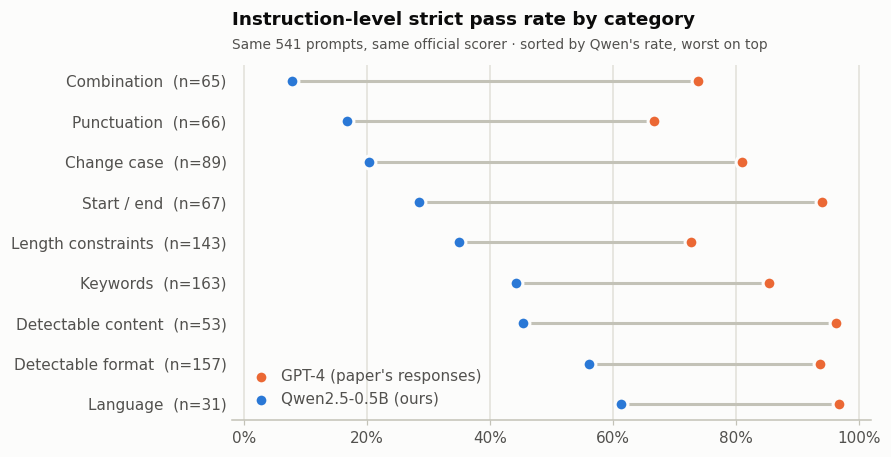

| Category | n | Qwen 0.5B | GPT-4 | Gap (points) |
|---|---|---|---|---|
| Combination | 65 | 7.7% | 73.8% | -66.2 |
| Punctuation | 66 | 16.7% | 66.7% | -50.0 |
| Change case | 89 | 20.2% | 80.9% | -60.7 |
| Start / end | 67 | 28.4% | 94.0% | -65.7 |
| Length constraints | 143 | 35.0% | 72.7% | -37.8 |
| Keywords | 163 | 44.2% | 85.3% | -41.1 |
| Detectable content | 53 | 45.3% | 96.2% | -50.9 |
| Detectable format | 157 | 56.1% | 93.6% | -37.6 |
| Language | 31 | 61.3% | 96.8% | -35.5 |

In [7]:
CATEGORY_NAMES = {
    "change_case": "Change case", "combination": "Combination", "detectable_content": "Detectable content",
    "detectable_format": "Detectable format", "keywords": "Keywords", "language": "Language",
    "length_constraints": "Length constraints", "punctuation": "Punctuation", "startend": "Start / end",
}


def dumbbell(qwen, gpt, labels, heading, sub, name, height):
    """One row per group: GPT-4 and Qwen dots joined by a hairline. Worst Qwen rate on top."""
    order = sorted(qwen, key=lambda g: qwen[g][0] / qwen[g][1], reverse=True)
    fig, ax = plt.subplots(figsize=(7.5, height))
    for y, g in enumerate(order):
        q = 100 * qwen[g][0] / qwen[g][1]
        o = 100 * gpt[g][0] / gpt[g][1]
        ax.plot([q, o], [y, y], color=AXIS, lw=2, zorder=1)
        ax.scatter([o], [y], color=GPT4, label="GPT-4 (paper's responses)" if y == 0 else None, **DOT)
        ax.scatter([q], [y], color=QWEN, label="Qwen2.5-0.5B (ours)" if y == 0 else None, **DOT)
    ax.set_yticks(range(len(order)), [labels(g) for g in order])
    ax.tick_params(axis="y", length=0)
    ax.set_xlim(-2, 102)
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.grid(axis="y", visible=False)
    ax.legend(loc="lower left", handletextpad=0.3, labelcolor=INK_2)
    title(ax, heading, sub)
    save(fig, name)
    return order


q_cat = rates_by(BASELINE, lambda iid: iid.split(":")[0])
g_cat = rates_by(REF, lambda iid: iid.split(":")[0])
order = dumbbell(q_cat, g_cat, lambda g: f"{CATEGORY_NAMES[g]}  (n={q_cat[g][1]})",
                 "Instruction-level strict pass rate by category",
                 "Same 541 prompts, same official scorer · sorted by Qwen's rate, worst on top",
                 "03_by_category", 4.2)
table(["Category", "n", "Qwen 0.5B", "GPT-4", "Gap (points)"],
      [[CATEGORY_NAMES[g], q_cat[g][1], pct(*q_cat[g]), pct(*g_cat[g]),
        f"{100 * (q_cat[g][0] / q_cat[g][1] - g_cat[g][0] / g_cat[g][1]):+.1f}"]
       for g in reversed(order)])

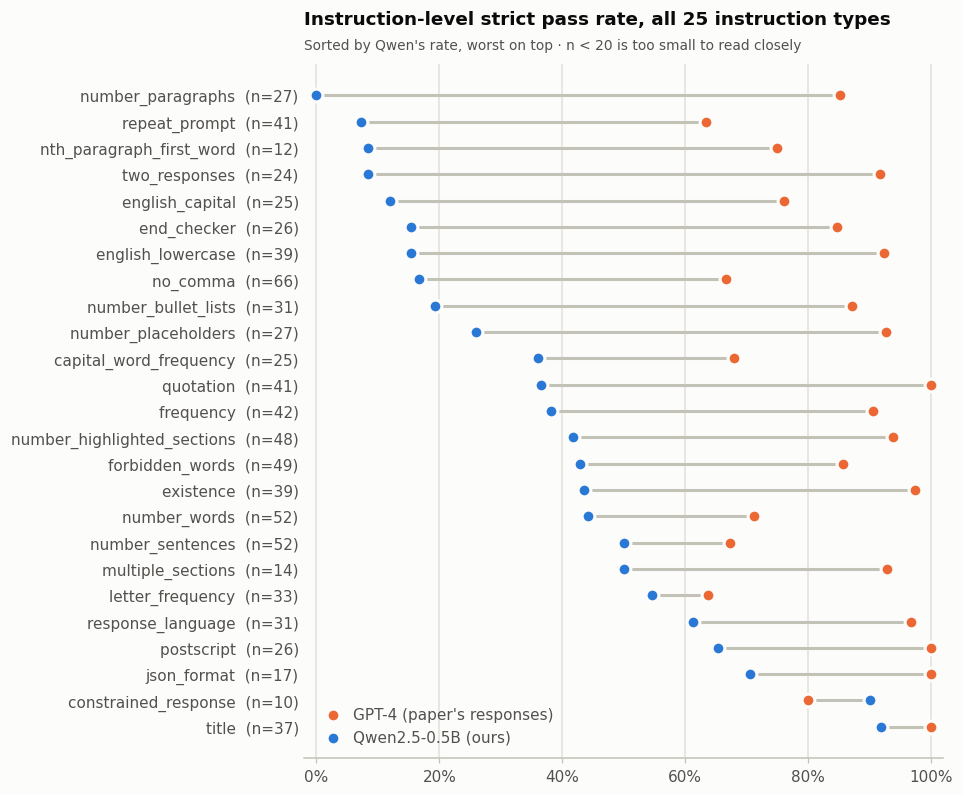

| Instruction type | n | Qwen 0.5B | GPT-4 |
|---|---|---|---|
| `length_constraints:number_paragraphs` | 27 | 0.0% (0/27) | 85.2% |
| `combination:repeat_prompt` | 41 | 7.3% (3/41) | 63.4% |
| `length_constraints:nth_paragraph_first_word` | 12 | 8.3% (1/12) | 75.0% |
| `combination:two_responses` | 24 | 8.3% (2/24) | 91.7% |
| `change_case:english_capital` | 25 | 12.0% (3/25) | 76.0% |
| `startend:end_checker` | 26 | 15.4% (4/26) | 84.6% |
| `change_case:english_lowercase` | 39 | 15.4% (6/39) | 92.3% |
| `punctuation:no_comma` | 66 | 16.7% (11/66) | 66.7% |
| `detectable_format:number_bullet_lists` | 31 | 19.4% (6/31) | 87.1% |
| `detectable_content:number_placeholders` | 27 | 25.9% (7/27) | 92.6% |
| `change_case:capital_word_frequency` | 25 | 36.0% (9/25) | 68.0% |
| `startend:quotation` | 41 | 36.6% (15/41) | 100.0% |
| `keywords:frequency` | 42 | 38.1% (16/42) | 90.5% |
| `detectable_format:number_highlighted_sections` | 48 | 41.7% (20/48) | 93.8% |
| `keywords:forbidden_words` | 49 | 42.9% (21/49) | 85.7% |
| `keywords:existence` | 39 | 43.6% (17/39) | 97.4% |
| `length_constraints:number_words` | 52 | 44.2% (23/52) | 71.2% |
| `length_constraints:number_sentences` | 52 | 50.0% (26/52) | 67.3% |
| `detectable_format:multiple_sections` | 14 | 50.0% (7/14) | 92.9% |
| `keywords:letter_frequency` | 33 | 54.5% (18/33) | 63.6% |
| `language:response_language` | 31 | 61.3% (19/31) | 96.8% |
| `detectable_content:postscript` | 26 | 65.4% (17/26) | 100.0% |
| `detectable_format:json_format` | 17 | 70.6% (12/17) | 100.0% |
| `detectable_format:constrained_response` | 10 | 90.0% (9/10) | 80.0% |
| `detectable_format:title` | 37 | 91.9% (34/37) | 100.0% |

In [8]:
q_type = rates_by(BASELINE, lambda iid: iid)
g_type = rates_by(REF, lambda iid: iid)
order = dumbbell(q_type, g_type, lambda g: f"{g.split(':')[1]}  (n={q_type[g][1]})",
                 "Instruction-level strict pass rate, all 25 instruction types",
                 "Sorted by Qwen's rate, worst on top · n < 20 is too small to read closely",
                 "04_by_instruction_type", 8.2)
table(["Instruction type", "n", "Qwen 0.5B", "GPT-4"],
      [[f"`{g}`", q_type[g][1], f"{pct(*q_type[g])} ({q_type[g][0]}/{q_type[g][1]})", pct(*g_type[g])]
       for g in reversed(order)])

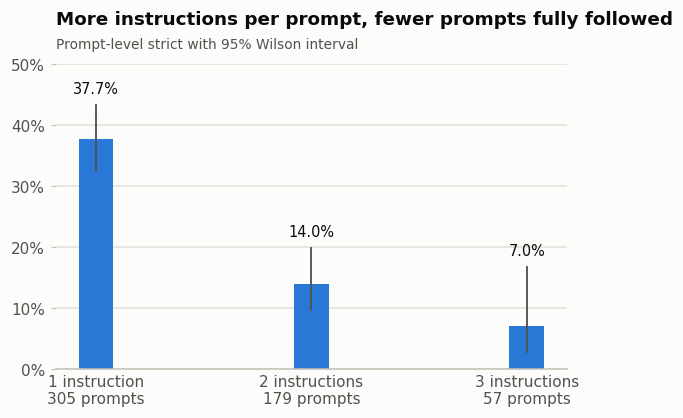

| Instructions in prompt | Prompts | Fully followed | Rate |
|---|---|---|---|
| 1 | 305 | 115 | 37.7% |
| 2 | 179 | 25 | 14.0% |
| 3 | 57 | 4 | 7.0% |

In [9]:
by_count = collections.defaultdict(lambda: [0, 0])
for r in read_jsonl(BASELINE / "eval_results_strict.jsonl"):
    by_count[len(r["instruction_id_list"])][0] += r["follow_all_instructions"]
    by_count[len(r["instruction_id_list"])][1] += 1
counts = sorted(by_count)

fig, ax = plt.subplots(figsize=(6, 3.6))
for x in counts:
    k, n = by_count[x]
    lo, hi = wilson(k, n)
    ax.bar(x, 100 * k / n, width=0.16, color=QWEN, zorder=2)   # thin mark, ~24px
    ax.plot([x, x], [100 * lo, 100 * hi], color=INK_2, lw=1.2, zorder=3)
    ax.text(x, 100 * hi + 1.5, f"{100 * k / n:.1f}%", ha="center", va="bottom", fontsize=9.5)
ax.set_xticks(counts, [f"{x} instruction{'s' if x > 1 else ''}\n{by_count[x][1]} prompts" for x in counts])
ax.tick_params(axis="x", length=0)
ax.set_ylim(0, 50)
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.grid(axis="x", visible=False)
title(ax, "More instructions per prompt, fewer prompts fully followed",
      "Prompt-level strict with 95% Wilson interval")
save(fig, "05_by_instruction_count")

table(["Instructions in prompt", "Prompts", "Fully followed", "Rate"],
      [[x, by_count[x][1], by_count[x][0], pct(*by_count[x])] for x in counts])

## 5. Response length and truncation

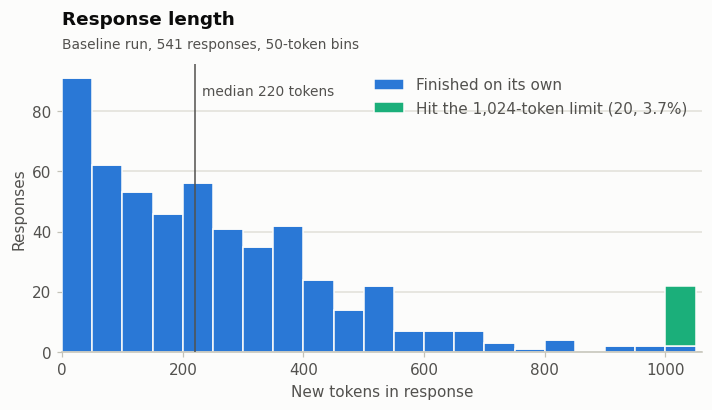

| Median | 90th percentile | Truncated | Truncated but still passed | Max gain if all truncated passed |
|---|---|---|---|---|
| 220 | 550 | 20 (3.7%) | 8 / 20 | +2.2 points |

In [10]:
gens = read_jsonl(BASELINE / "generations.jsonl")
complete = [g["n_new_tokens"] for g in gens if not g["truncated"]]
cut_off = [g["n_new_tokens"] for g in gens if g["truncated"]]
lengths = sorted(g["n_new_tokens"] for g in gens)
median = lengths[len(lengths) // 2]

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.hist([complete, cut_off], bins=range(0, 1051, 50), stacked=True, color=[QWEN, TRUNCATED],
        edgecolor=SURFACE, linewidth=1, zorder=2,
        label=["Finished on its own", f"Hit the 1,024-token limit ({len(cut_off)}, {pct(len(cut_off), len(gens))})"])
ax.axvline(median, color=INK_2, lw=1, zorder=3)
ax.text(median + 12, ax.get_ylim()[1] * 0.93, f"median {median} tokens", color=INK_2, fontsize=9, va="top")
ax.set_xlim(0, 1060)
ax.set_xlabel("New tokens in response")
ax.set_ylabel("Responses")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right", labelcolor=INK_2)
title(ax, "Response length", "Baseline run, 541 responses, 50-token bins")
save(fig, "06_response_length")

truncated_pass = sum(1 for r in read_jsonl(BASELINE / "eval_results_strict.jsonl")
                     for g in gens if g["truncated"] and g["prompt"] == r["prompt"] and r["follow_all_instructions"])
table(["Median", "90th percentile", "Truncated", "Truncated but still passed", "Max gain if all truncated passed"],
      [[median, lengths[int(len(lengths) * 0.9)], f"{len(cut_off)} ({pct(len(cut_off), len(gens))})",
        f"{truncated_pass} / {len(cut_off)}", f"+{100 * (len(cut_off) - truncated_pass) / len(gens):.1f} points"]])

## 6. Sensitivity to the system prompt

Only `prompt.system_prompt` differs between these runs. *Gained* = failed in the
baseline, passed with the variant (prompt-level strict); *lost* = the reverse.
p is an exact McNemar test on those paired prompts.

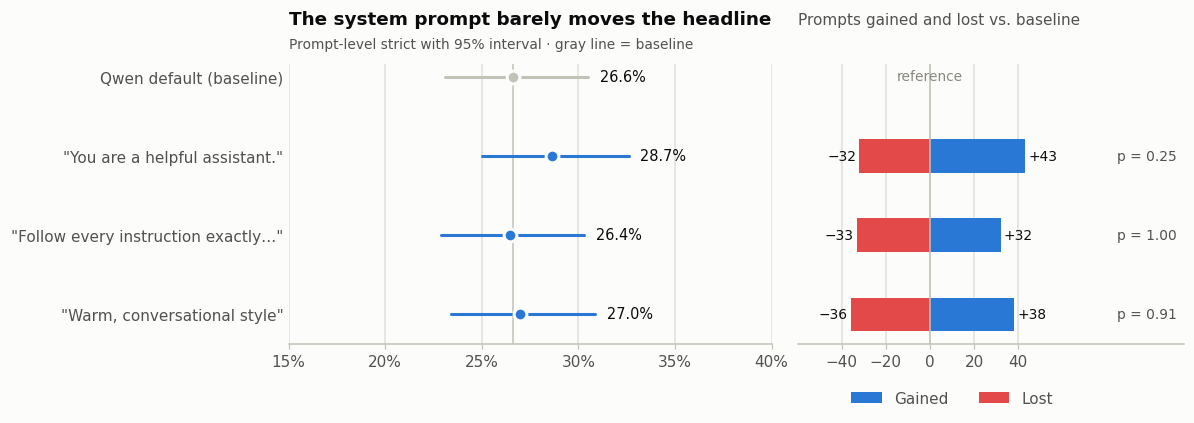

| System prompt | Prompt strict | Instruction strict | Prompt loose | Instruction loose | Truncated | Gained / lost | p |
|---|---|---|---|---|---|---|---|
| Qwen default (baseline) | 26.6% | 36.7% | 29.0% | 39.1% | 3.7% | — | — |
| "You are a helpful assistant." | 28.7% | 39.9% | 31.8% | 43.6% | 6.1% | +43 / −32 | 0.25 |
| "Follow every instruction exactly…" | 26.4% | 37.4% | 29.6% | 41.2% | 2.8% | +32 / −33 | 1.00 |
| "Warm, conversational style" | 27.0% | 36.8% | 29.6% | 39.6% | 3.7% | +38 / −36 | 0.91 |

In [11]:
def mcnemar_exact(b, c):
    """Two-sided exact McNemar p-value: binomial test on the discordant pairs."""
    n = b + c
    return 1.0 if n == 0 else min(1.0, 2 * sum(math.comb(n, i) for i in range(min(b, c) + 1)) / 2 ** n)


base_pass = prompt_pass(BASELINE)
results = []
for label, run in VARIANTS.items():
    passed = prompt_pass(run)
    gained = sum(1 for p in passed if passed[p] and not base_pass[p])
    lost = sum(1 for p in passed if base_pass[p] and not passed[p])
    results.append((label, run, four_metrics(run), gained, lost, mcnemar_exact(gained, lost)))

fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 3.3), sharey=True,
                                  gridspec_kw={"width_ratios": [1.25, 1], "wspace": 0.06})
base_rate = 100 * results[0][2]["Prompt strict"][0] / 541
left.axvline(base_rate, color=AXIS, lw=1, zorder=1)
for y, (label, run, m, gained, lost, p) in enumerate(reversed(results)):
    k, n = m["Prompt strict"]
    lo, hi = wilson(k, n)
    colour = CONTEXT if run == BASELINE else QWEN
    left.plot([100 * lo, 100 * hi], [y, y], color=colour, lw=2, solid_capstyle="round", zorder=2)
    left.scatter([100 * k / n], [y], color=colour, **DOT)
    left.text(100 * hi + 0.6, y, f"{100 * k / n:.1f}%", va="center", fontsize=9.5)
    if run == BASELINE:
        right.text(0, y, "reference", ha="center", va="center", color=MUTED, fontsize=9)
        continue
    right.barh(y, gained, height=0.42, color=GAINED, label="Gained" if y == 0 else None, zorder=2)
    right.barh(y, -lost, height=0.42, color=LOST, label="Lost" if y == 0 else None, zorder=2)
    right.text(gained + 1.5, y, f"+{gained}", va="center", fontsize=9)
    right.text(-lost - 1.5, y, f"−{lost}", va="center", ha="right", fontsize=9)
    right.text(112, y, f"p = {p:.2f}", va="center", ha="right", color=INK_2, fontsize=9)
left.set_yticks(range(len(results)), [r[0] for r in reversed(results)])
left.tick_params(axis="y", length=0)
left.set_xlim(15, 40)
left.xaxis.set_major_formatter(PercentFormatter(decimals=0))
left.grid(axis="y", visible=False)
title(left, "The system prompt barely moves the headline",
      "Prompt-level strict with 95% interval · gray line = baseline")
right.axvline(0, color=AXIS, lw=1)
right.set_xlim(-60, 115)
right.set_xticks([-40, -20, 0, 20, 40])
right.grid(axis="y", visible=False)
right.tick_params(axis="y", length=0)
right.set_title("Prompts gained and lost vs. baseline", fontsize=10, fontweight="normal", color=INK_2, pad=26)
right.legend(loc="upper center", bbox_to_anchor=(0.4, -0.12), ncol=2, labelcolor=INK_2)
save(fig, "07_system_prompt")

table(["System prompt", *METRICS, "Truncated", "Gained / lost", "p"],
      [[label, *(pct(*m[x]) for x in METRICS),
        pct(sum(g["truncated"] for g in read_jsonl(run / "generations.jsonl")), 541),
        "—" if run == BASELINE else f"+{gained} / −{lost}", "—" if run == BASELINE else f"{p:.2f}"]
       for label, run, m, gained, lost, p in results])

## Saved figures

All charts above are written to `report/figures/` at 200 dpi for slides.

In [12]:
for path in sorted(FIGURES.glob("*.png")):
    print(path.relative_to(ROOT))

report/figures/01_headline_metrics.png
report/figures/02_published_comparison.png
report/figures/03_by_category.png
report/figures/04_by_instruction_type.png
report/figures/05_by_instruction_count.png
report/figures/06_response_length.png
report/figures/07_system_prompt.png
